# P2. 날씨 × 따릉이 수요

서울시 강우량계 48곳의 10분 강우량과 따릉이 한 달 대여 기록을 날짜 · 자치구 키로 맞춰 조인하고, Spark 와 DuckDB 로 「비 오는 평일에 대여가 얼마나 줄어드나」를 구합니다.

- 단계: 개별 프로젝트 · 정형 · 예상 2~3일
- 실행 환경: Google Colab(브라우저만 있으면 됩니다)
- 데이터: 서울 열린데이터광장 — 서울특별시 공공자전거 대여이력 정보(OA-15182) 2025년 6월분을 날짜 × 대여소로 센 표, 공공누리 1유형(출처표시)
- 데이터: 서울 열린데이터광장 — 공공자전거 대여소 정보(OA-13252) 2025년 6월 기준, 공공누리 1유형
- 데이터: 서울 열린데이터광장 — 서울시 강우량 데이터(OA-22715) 2025년 파일 중 6월분, 공공누리 1유형
- 데이터: 서울 열린데이터광장 — 서울시 강우량계 위치데이터(OA-22824), 공공누리 1유형
- 데이터: (선택) 공공데이터포털 — 기상청 지상(종관, ASOS) 일자료 조회서비스, 인증키 필요

셀을 위에서부터 차례로 실행하세요. 각 단계 끝의 **확인 포인트** 숫자가 같게 나오면 다음 단계로 갑니다.
따라하기를 한 번 끝냈다면 같은 내용의 [빈칸 노트북](https://colab.research.google.com/github/aebonlee/materials/blob/main/data-eng/projects/P2/P2_blank.ipynb)으로 다시 쳐 보세요.

비가 오면 자전거를 덜 탑니다. 누구나 아는 이야기지만 「얼마나」 덜 타는지는 숫자로 답해 본 적이 드뭅니다.
이 프로젝트에서는 서울시가 공개한 두 데이터 — 따릉이 대여 기록과 구청 강우량계 기록 — 를 이어 붙여 **「비 오는 평일의 대여 감소율」**을 자치구마다 구합니다.

두 데이터는 만든 기관도, 만든 목적도 다릅니다. 그래서 그대로는 이어지지 않습니다.

- 따릉이 대여소 번호는 `00102` 처럼 다섯 자리인데, 대여소 정보 엑셀에는 `102` 로 적혀 있습니다.
- 강우량 파일 48개는 글자 인코딩도, 따옴표도, 줄 끝도 파일마다 다릅니다. 같은 시각이 두 번 적힌 강우량계도 있습니다.
- 강우량은 10분 단위 · 강우량계 단위이고, 대여는 하루 단위 · 대여소 단위입니다.

이 차이를 하나씩 맞추는 **정제**가 이 프로젝트의 핵심입니다. 흐름은 이렇습니다.

```text
따릉이(날짜 × 대여소) ─ 대여소 정보(대여소 → 자치구) ─┐
                                                      ├─ 키: (날짜, 자치구) ─ Spark 조인 · 집계 ─ DuckDB 로 대조
강우량 10분 자료 48개 ─ 강우량계 위치(강우량계 → 자치구) ┘
```

다 끝내면 다음을 말할 수 있습니다.

- 비 오는 평일에 서울 전체 대여가 맑은 평일보다 몇 % 줄어드는지
- 비에 가장 민감한 자치구와 가장 덜 민감한 자치구
- 출처가 다른 두 데이터를 잇기 전에 무엇을 확인해야 하는지

## 1단계 · 준비 — 라이브러리 · Java · 데이터

이번에는 5주차에 배운 Spark(PySpark)를 씁니다. Spark 는 Java 위에서 돌기 때문에 Java 가 있는지 먼저 확인하고, 없으면 설치합니다.
엑셀 파일을 읽는 `openpyxl` 도 확인합니다. Colab 에는 대개 둘 다 있어서 이 셀은 금방 끝납니다.

In [ ]:
import os, sys, io, shutil, zipfile, subprocess, importlib.util, urllib.request
import pandas as pd
import numpy as np
import duckdb

def need(mod, pkg=None):
    """없는 패키지만 설치합니다."""
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg or mod], check=True)

need("pyspark")
need("openpyxl")

if shutil.which("java") is None:                      # Colab 에 Java 가 없을 때만 설치합니다
    subprocess.run("apt-get install -y -qq openjdk-17-jre-headless > /dev/null", shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0])

openjdk version "21.0.11" 2026-04-21 LTS


데이터는 공개 자료실에서 받습니다. 네 파일 모두 서울 열린데이터광장의 자료이고 이용허락은 **공공누리 1유형(출처표시)** 입니다.

| 파일 | 원본 데이터셋 | 손댄 것 |
|---|---|---|
| `seoul_bike_daily_station_202506.csv.gz` | 서울특별시 공공자전거 대여이력 정보(OA-15182) 2025년 6월 | 402만 건을 날짜 × 대여소로 센 표 |
| `seoul_bike_station_202506.xlsx` | 공공자전거 대여소 정보(OA-13252) 「25.6월 기준」 파일(2025-06-18 설치분까지 2,780곳) | 없음(원본 그대로) |
| `seoul_rain_10min_202506.zip` | 서울시 강우량 데이터(OA-22715) 2025년 | 강우량계 48개 파일에서 6월 줄만 남김(인코딩 · 형식은 원본 그대로) |
| `seoul_rain_gauge_location.xlsx` | 서울시 강우량계 위치데이터(OA-22824) | 없음(원본 그대로) |

2026년 강우량 파일은 아직 공개되지 않아(2025년분까지 공개) 두 데이터가 모두 있는 **2025년 6월**을 고릅니다.

In [ ]:
DATA = "https://raw.githubusercontent.com/aebonlee/materials/main/data-eng/projects/data/"

def fetch(name):
    """프로젝트 데이터를 ./data 폴더에 한 번만 받아 둡니다."""
    os.makedirs("data", exist_ok=True)
    dst = os.path.join("data", name)
    if not os.path.exists(dst):
        local = os.environ.get("DE_DATA_LOCAL")          # 오프라인 실습용 — 자료 폴더가 내 컴퓨터에 있을 때
        if local:
            shutil.copy(os.path.join(local, name), dst)
        else:
            urllib.request.urlretrieve(DATA + name, dst)
    return dst

BIKE = fetch("seoul_bike_daily_station_202506.csv.gz")
STATION = fetch("seoul_bike_station_202506.xlsx")
RAIN = fetch("seoul_rain_10min_202506.zip")
GAUGE = fetch("seoul_rain_gauge_location.xlsx")
for p in (BIKE, STATION, RAIN, GAUGE):
    print(p, round(os.path.getsize(p) / 1e6, 2), "MB")

data/seoul_bike_daily_station_202506.csv.gz 1.3 MB
data/seoul_bike_station_202506.xlsx 0.29 MB
data/seoul_rain_10min_202506.zip 7.03 MB
data/seoul_rain_gauge_location.xlsx 0.01 MB


> **확인 포인트** — 네 파일이 `data/` 에 받아지고 가장 큰 것은 강우량 zip(7.03 MB)입니다.

In [ ]:
assert round(os.path.getsize(RAIN) / 1e6, 2) == 7.03

> **Aebon's Tip** — 대여 기록 원본(한 달 약 750MB)에서 직접 세어 보고 싶으면 OA-15182 에서 2025년 zip 을 받아 6월 CSV 를 꺼낸 뒤 아래 SQL 을 DuckDB 로 돌리세요(14~15장).
> 원본은 CP949 라 먼저 UTF-8 로 바꿔 두면 편합니다(`iconv -f cp949 -t utf-8`). 이 프로젝트의 스냅샷도 이 SQL 로 만들었습니다.

```sql
SELECT substr("대여일시", 1, 10) AS rent_date, "대여 대여소번호" AS station_id,
       any_value("대여 대여소명") AS station_name, count(*) AS rentals,
       sum(try_cast("이용시간(분)" AS int)) AS use_min
FROM read_csv('bike2506_utf8.csv', all_varchar = true, header = true)
GROUP BY 1, 2 ORDER BY 1, 2;
```

## 2단계 · 따릉이 — 날짜 × 대여소 표 읽기

대여소 번호는 글자로 읽습니다. 숫자로 읽으면 `00102` 의 앞자리 0이 사라져 `102` 가 됩니다(M1 과 같은 이유).

In [ ]:
bike = pd.read_csv(BIKE, dtype={"station_id": str})
print(bike.shape, "대여 합계:", bike["rentals"].sum())
bike.head(3)

(81254, 5) 대여 합계: 4024309


,rent_date,station_id,station_name,rentals,use_min
0,2025-06-01,00102,망원역 1번출구 앞,154,4884
1,2025-06-01,00103,망원역 2번출구 앞,166,5059
2,2025-06-01,00104,합정역 1번출구 앞,47,1009


> **확인 포인트** — `(81254, 5)` — 30일 × 약 2,700곳, 대여 합계는 **4,024,309건**입니다.

In [ ]:
assert bike.shape == (81254, 5) and bike["rentals"].sum() == 4024309

`rent_date` 는 지금 글자입니다. 요일을 꺼내려 하면 실패합니다. 실패를 본 뒤 날짜로 바꿉니다.

In [ ]:
try:
    bike["rent_date"].dt.dayofweek
except AttributeError as e:
    print("실패:", e)

실패: Can only use .dt accessor with datetimelike values


In [ ]:
bike["rent_date"] = pd.to_datetime(bike["rent_date"])
daily_total = bike.groupby("rent_date")["rentals"].sum()
print(daily_total.idxmin().date(), daily_total.min())

2025-06-20 13179


> **확인 포인트** — 한 달 중 가장 적게 빌린 날은 **2025-06-20, 13,179건**입니다. 다른 평일은 15만 건 안팎입니다 — 이날 무슨 일이 있었는지는 4단계에서 강우량으로 확인합니다.

In [ ]:
assert str(daily_total.idxmin().date()) == "2025-06-20" and daily_total.min() == 13179

## 3단계 · 대여소 → 자치구 — 번호 모양 맞추기

강우량은 자치구마다 있으니 대여도 자치구로 묶어야 합니다. 대여소 정보 엑셀에 대여소마다 자치구가 적혀 있습니다.
먼저 머리 없이 그대로 읽어 모양을 봅니다. 공공기관 엑셀은 위쪽 여러 줄이 병합된 제목인 경우가 많습니다.

In [ ]:
raw_st = pd.read_excel(STATION, header=None, dtype=str)
print(raw_st.shape)
raw_st.head(7)

(2785, 10)


,0,1,2,3,4,5,6,7,8,9
0,대여소\n번호,보관소(대여소)명,소재지(위치),NaN,NaN,NaN,설치\n시기,설치형태,NaN,운영\n방식
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,LCD,QR,NaN
2,NaN,NaN,자치구,상세주소,위도,경도,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,거치\n대수,거치\n대수,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,301,경복궁역 7번출구 앞,종로구,서울특별시 종로구 사직로 지하130 경복궁역 7번출구 앞,37.57579422,126.97145081,2015-10-07 12:03:46,NaN,20,QR
6,302,경복궁역 4번출구 뒤,종로구,서울특별시 종로구 사직로 지하130 경복궁역 4번출구 뒤,37.57594681,126.97406006,2015-10-07 12:04:22,NaN,12,QR


위 5줄(0~4행)이 제목이고 6번째 줄부터가 데이터입니다. 쓸 열만 골라 이름을 붙입니다.

In [ ]:
st = pd.read_excel(STATION, header=None, skiprows=5, dtype=str).iloc[:, [0, 1, 2, 4, 5]]
st.columns = ["station_no", "station_name", "gu", "lat", "lon"]
print(st.shape, "자치구 수:", st["gu"].nunique())
st.head(3)

(2780, 5) 자치구 수: 25


,station_no,station_name,gu,lat,lon
0,301,경복궁역 7번출구 앞,종로구,37.57579422,126.97145081
1,302,경복궁역 4번출구 뒤,종로구,37.57594681,126.97406006
2,303,광화문역 1번출구 앞,종로구,37.57176971,126.97466278


> **확인 포인트** — 대여소 **2,780곳**, 자치구 **25개**입니다.

In [ ]:
assert len(st) == 2780 and st["gu"].nunique() == 25

이제 일부러 그대로 이어 붙여 봅니다. 두 표의 번호 모양이 달라 하나도 이어지지 않습니다.

In [ ]:
try:
    m = bike.merge(st, left_on="station_id", right_on="station_no", how="inner")
    assert len(m) > 0, "이어진 행이 0개 — 번호 모양을 확인하세요"
except AssertionError as e:
    print("조인 실패:", e)
    print("따릉이:", bike["station_id"].iloc[0], "/ 대여소 정보:", st["station_no"].iloc[0])

조인 실패: 이어진 행이 0개 — 번호 모양을 확인하세요
따릉이: 00102 / 대여소 정보: 301


엑셀 쪽 번호는 3~4자리, 따릉이 쪽은 앞을 0으로 채운 5자리입니다. 엑셀 쪽을 5자리로 맞춥니다.

In [ ]:
st["station_id"] = st["station_no"].str.zfill(5)
assert st["station_id"].is_unique

bike_gu = bike.merge(st[["station_id", "gu"]], on="station_id", how="left", indicator=True)
miss = bike_gu[bike_gu["_merge"] == "left_only"]
print("자치구를 못 찾은 대여소:", miss["station_id"].nunique(), "곳,", miss["rentals"].sum(), "건",
      f"({miss['rentals'].sum() / bike['rentals'].sum():.2%})")

자치구를 못 찾은 대여소: 1 곳, 964 건 (0.02%)


> **확인 포인트** — 자치구를 못 찾은 대여소 **1곳, 964건(0.02%)** 입니다 — 6월 1일부터 대여가 있었던 「한강버스 마곡 선착장」(06184)이 6월 기준 목록에는 아직 없습니다.
> 마스터 자료가 실제 운영보다 늦게 고쳐지는 일은 흔합니다. 0.1%도 안 되므로 빼고 갑니다.

In [ ]:
assert miss["station_id"].nunique() == 1 and miss["rentals"].sum() == 964
bike_gu = bike_gu[bike_gu["_merge"] == "both"].drop(columns="_merge")

> **Aebon's Tip** — 빠진 대여소를 살리고 싶으면 OA-13252 의 「25.12월 기준」 파일을 받아 같은 방식으로 한 번 더 이어 보세요(그 목록에는 06184 가 강서구로 들어 있습니다). 마스터 자료는 **기준 시점**을 꼭 확인합니다.

## 4단계 · 강우량 파일 48개 — 인코딩 · 시각 · 중복 정리

zip 안에는 강우량계 하나당 CSV 하나, 모두 48개가 들어 있습니다. 첫 줄은 `2025년` 같은 제목이고 둘째 줄이 열 이름입니다.
먼저 모두 UTF-8 이라고 생각하고 읽어 봅니다.

In [ ]:
zf = zipfile.ZipFile(RAIN)
names = zf.namelist()
print(len(names), names[:3])

bad = []
for n in names:
    try:
        zf.read(n).decode("utf-8")
    except UnicodeDecodeError:
        bad.append(n)
print("UTF-8 로 못 읽은 파일:", len(bad))

48 ['가산2펌프장_202506.csv', '갈현1동_202506.csv', '강남구청_202506.csv']
UTF-8 로 못 읽은 파일: 37


> **확인 포인트** — 48개 중 **37개**가 UTF-8 이 아닙니다(CP949). 같은 데이터셋 안에서도 파일마다 인코딩이 다를 수 있습니다.

In [ ]:
assert len(names) == 48 and len(bad) == 37

UTF-8 로 먼저 읽어 보고, 안 되면 CP949 로 읽는 함수를 만듭니다. 따옴표와 줄 끝(`\r\n`)이 파일마다 다른 것은 `read_csv` 가 알아서 처리합니다.

In [ ]:
def read_gauge(raw: bytes) -> pd.DataFrame:
    try:
        text = raw.decode("utf-8-sig")
    except UnicodeDecodeError:
        text = raw.decode("cp949")
    return pd.read_csv(io.StringIO(text), skiprows=1, dtype=str)

rain = pd.concat([read_gauge(zf.read(n)) for n in names], ignore_index=True)
rain.columns = ["gauge", "ts", "mm"]
rain["mm"] = pd.to_numeric(rain["mm"])
print(rain.shape)
rain.head(3)

(210563, 3)


,gauge,ts,mm
0,가산2P,2025-06-01 00:09,0.0
1,가산2P,2025-06-01 00:19,0.0
2,가산2P,2025-06-01 00:29,0.0


> **확인 포인트** — `(210563, 3)` 입니다.

In [ ]:
assert rain.shape == (210563, 3)

시각을 날짜로 바꿉니다. 형식을 `%Y-%m-%d %H:%M` 으로 못박으면 실패합니다 — 초까지 적힌 줄이 섞여 있기 때문입니다.

In [ ]:
try:
    pd.to_datetime(rain["ts"], format="%Y-%m-%d %H:%M")
except ValueError as e:
    print("실패:", str(e).splitlines()[0][:90])

실패: unconverted data remains when parsing with format "%Y-%m-%d %H:%M": ":59", at position 416


In [ ]:
rain["ts"] = pd.to_datetime(rain["ts"], format="mixed")
print(rain["ts"].min(), "~", rain["ts"].max())

2025-06-01 00:09:00 ~ 2025-06-30 23:59:00


이번에는 중복입니다. 강우량계 하나 · 시각 하나에는 기록이 한 줄이어야 합니다.

In [ ]:
dup = rain.duplicated(["gauge", "ts"], keep=False)
print("중복 줄:", dup.sum(), "/ 강우량계:", rain.loc[dup, "gauge"].unique())

g = rain[dup].groupby("ts")["mm"].agg(["min", "max"])
print("같은 시각인데 값이 다른 곳:", (g["min"] != g["max"]).sum(), "/ 그중 둘 다 0이 아닌 곳:", ((g["min"] > 0)).sum())

중복 줄: 8640 / 강우량계: ['신림P']
같은 시각인데 값이 다른 곳: 106 / 그중 둘 다 0이 아닌 곳: 0


> **확인 포인트** — 중복은 **신림P 한 곳에서만 8,640줄**(4,320시각 × 2줄)입니다.
> 값이 다른 106시각은 언제나 한쪽이 0이고, 둘 다 0이 아닌 곳은 없습니다. 그래서 같은 시각의 두 줄 가운데 **큰 값 하나**를 남깁니다.

In [ ]:
assert dup.sum() == 8640 and (g["min"] != g["max"]).sum() == 106 and (g["min"] > 0).sum() == 0

rain = rain.groupby(["gauge", "ts"], as_index=False)["mm"].max()
print(rain.shape)
assert len(rain) == 206243

(206243, 3)


> **자주 겪는 오류** — 중복을 `drop_duplicates()` 로만 지우면 값이 다른 106줄은 그대로 남아 신림P 의 비가 두 배 가까이 셈해집니다.
> 「완전히 같은 줄」과 「키만 같은 줄」은 따로 세어 보세요.

이제 강우량계마다 하루치를 더하고, 강우량계 위치 자료로 자치구를 붙입니다.
파일 이름(`가산2펌프장`)과 파일 안 이름(`가산2P`)이 다르니, 잇는 키는 **파일 안의 강우량계명**입니다.

In [ ]:
gauge = pd.read_excel(GAUGE, dtype=str)[["구청명", "강우량계명"]]
gauge.columns = ["gu", "gauge"]

print("위치 자료에 없는 강우량계:", set(rain["gauge"]) - set(gauge["gauge"]))
assert set(rain["gauge"]) <= set(gauge["gauge"])

rain["date"] = rain["ts"].dt.normalize()
gauge_day = rain.groupby(["gauge", "date"], as_index=False)["mm"].sum()
gu_rain = (gauge_day.merge(gauge, on="gauge")
           .groupby(["gu", "date"], as_index=False)["mm"].mean()
           .rename(columns={"mm": "rain_mm"}))
print(gu_rain.shape)
gu_rain.sort_values("rain_mm", ascending=False).head(3)

위치 자료에 없는 강우량계: set()


(750, 3)


,gu,date,rain_mm
109,강서구,2025-06-20,67.5
409,서대문구,2025-06-20,65.0
559,양천구,2025-06-20,64.0


> **확인 포인트** — `(750, 3)` — 25개 구 × 30일입니다. 가장 비가 많이 온 구-날은 6월 20일입니다.

In [ ]:
assert gu_rain.shape == (750, 3)
assert str(gu_rain.loc[gu_rain["rain_mm"].idxmax(), "date"].date()) == "2025-06-20"

> **Aebon's Tip** — 강우량 시각 `00:09` 의 값은 `23:59 ~ 00:09` 10분 동안 내린 비입니다. 자정 직후 10분은 엄밀히는 전날 몫이지만, 하루 합계에서는 차이가 거의 없어 날짜 그대로 씁니다.

## 5단계 · 기상청 ASOS 일자료와 견주기 — 인증키가 있을 때

구청 강우량계는 서울시가 운영하는 장비입니다. 공식 기상 관측은 기상청 종관기상관측(ASOS) 서울 지점(108)입니다.
공공데이터포털의 「기상청_지상(종관, ASOS) 일자료 조회서비스」에서 활용 신청을 하면 인증키를 받을 수 있습니다. 키가 없으면 이 단계는 건너뜁니다 — 다음 단계는 4단계의 `gu_rain` 만으로 진행됩니다.

먼저 일부러 엉터리 키로 불러 봅니다. 공공데이터포털은 키가 틀리면 데이터 대신 오류 메시지를 돌려줍니다.

In [ ]:
import requests

ASOS_URL = "https://apis.data.go.kr/1360000/AsosDalyInfoService/getWthrDataList"
params = {"pageNo": 1, "numOfRows": 31, "dataType": "JSON", "dataCd": "ASOS", "dateCd": "DAY",
          "startDt": "20250601", "endDt": "20250630", "stnIds": "108"}

try:
    r = requests.get(ASOS_URL, params={**params, "serviceKey": "wrong-key"}, timeout=10)
    print(r.status_code, r.text[:160])
except Exception as e:
    print("요청 실패:", type(e).__name__, str(e)[:80])

403 {
  "OpenAPI_ServiceResponse": {
    "cmmMsgHeader": {
      "errMsg": "SERVICE_KEY_IS_NOT_REGISTERED_ERROR",
      "returnAuthMsg": "등록되지 않은 서비스키",
      "retu


In [ ]:
def get_key(name):
    try:
        from google.colab import userdata          # Colab 왼쪽 열쇠 아이콘(보안 비밀)에 넣어 둔 값
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

KEY = get_key("DATA_GO_KR_KEY")
if KEY:
    r = requests.get(ASOS_URL, params={**params, "serviceKey": KEY}, timeout=20)
    items = r.json()["response"]["body"]["items"]["item"]
    asos = pd.DataFrame(items)[["tm", "sumRn", "avgTa"]]
    asos["date"] = pd.to_datetime(asos["tm"])
    asos["sumRn"] = pd.to_numeric(asos["sumRn"].replace("", "0"))   # 비가 안 온 날은 빈 글자로 옵니다
    seoul_mean = gu_rain.groupby("date", as_index=False)["rain_mm"].mean()
    cmp = asos.merge(seoul_mean, on="date")
    print(cmp[["date", "sumRn", "rain_mm"]].round(1).to_string(index=False))
    print("상관계수:", round(cmp["sumRn"].corr(cmp["rain_mm"]), 3))
else:
    print("DATA_GO_KR_KEY 가 없어 ASOS 비교를 건너뜁니다.")

DATA_GO_KR_KEY 가 없어 ASOS 비교를 건너뜁니다.


> **Aebon's Tip** — ASOS 는 서울 전체에 지점이 하나라 「구마다 다른 비」를 볼 수 없습니다. 구 단위로 잇고 싶어서 이 프로젝트는 구청 강우량계를 주 자료로 씁니다.
> 기상자료개방포털(data.kma.go.kr)에 가입하면 같은 ASOS 일자료와 자치구 근처 AWS(방재기상관측) 자료를 CSV 로도 받을 수 있습니다.

## 6단계 · Spark 로 조인 · 집계

이제 키가 맞았습니다. 대여는 (날짜, 대여소 → 자치구), 비는 (날짜, 자치구)입니다.
5주차에 배운 Spark 로 두 표를 (날짜, 자치구)로 잇고 「비 오는 평일 vs 맑은 평일」을 집계합니다. 데이터가 이 정도면 pandas 로도 되지만, 대여 기록이 몇 년치로 늘어도 **같은 코드**가 그대로 돈다는 것이 Spark 를 쓰는 이유입니다.

In [ ]:
from pyspark.sql import SparkSession, functions as F

os.environ["PYSPARK_PYTHON"] = sys.executable        # Spark 일꾼도 이 노트북과 같은 파이썬을 쓰게 합니다
spark = (SparkSession.builder.master("local[2]").appName("P2-weather-bike")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.enabled", "false")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.execution.arrow.pyspark.enabled", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print(spark.version)

3.5.3


> **자주 겪는 오류** — `PYSPARK_PYTHON` 을 정하지 않으면 컴퓨터에 파이썬이 여럿 깔린 경우 Spark 일꾼이 다른 판의 파이썬을 잡아 `PYTHON_VERSION_MISMATCH` 로 멈춥니다. 노트북의 `sys.executable` 로 맞춰 두면 Colab 에서도 로컬에서도 같게 돕니다.

따릉이 원본 표는 Spark 가 직접 읽습니다. 스키마를 적어 주어 대여소 번호를 글자로 읽게 합니다. 대여소 → 자치구 표와 구별 강우량 표는 pandas 에서 넘깁니다.

In [ ]:
schema = "rent_date DATE, station_id STRING, station_name STRING, rentals INT, use_min BIGINT"
b = spark.read.csv(BIKE, header=True, schema=schema)
s = spark.createDataFrame(st[["station_id", "gu"]])
r = spark.createDataFrame(gu_rain.assign(date=gu_rain["date"].dt.date))
print(b.count(), s.count(), r.count())

81254 2780 750


> **확인 포인트** — `81254 2780 750` 입니다.

In [ ]:
assert (b.count(), s.count(), r.count()) == (81254, 2780, 750)

없는 열 이름을 쓰면 Spark 는 실행 계획을 세우는 단계에서 바로 멈춥니다. 일부러 틀려 봅니다.

In [ ]:
from pyspark.errors import AnalysisException
try:
    b.select("rent_dt").show(1)
except AnalysisException as e:
    print("실패:", str(e).splitlines()[0][:100])

실패: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column or function parameter with name `rent_dt` cannot be res


공휴일 두 날(6/3 대통령 선거일, 6/6 현충일)과 주말은 평소와 타는 사람이 달라서 뺍니다. 비 오는 날은 구의 하루 강우량 1mm 이상으로 정합니다.

In [ ]:
HOLIDAYS = ["2025-06-03", "2025-06-06"]

gu_day = (b.join(s, "station_id", "inner")
           .groupBy("gu", "rent_date").agg(F.sum("rentals").alias("rentals")))

joined = (gu_day.join(r, (gu_day.gu == r.gu) & (gu_day.rent_date == r.date))
          .select(gu_day.gu, "rent_date", "rentals", "rain_mm")
          .withColumn("weekday", (F.dayofweek("rent_date").between(2, 6))
                                 & ~F.col("rent_date").cast("string").isin(HOLIDAYS))
          .withColumn("rainy", F.col("rain_mm") >= 1.0))
print(joined.count(), joined.filter("weekday").count())

750 475


> **확인 포인트** — 조인 결과 750행(25개 구 × 30일), 그중 공휴일을 뺀 평일이 **475행**(19일 × 25개 구)입니다.

In [ ]:
assert joined.count() == 750 and joined.filter("weekday").count() == 475

자치구마다 비 오는 평일과 맑은 평일의 하루 평균 대여를 구하고, 감소율 = 1 − 비 오는 날 평균 ÷ 맑은 날 평균 으로 계산합니다.

In [ ]:
wk = joined.filter("weekday")
by_gu = (wk.groupBy("gu").agg(
            F.avg(F.when(F.col("rainy"), F.col("rentals"))).alias("rainy_avg"),
            F.avg(F.when(~F.col("rainy"), F.col("rentals"))).alias("dry_avg"),
            F.sum(F.col("rainy").cast("int")).alias("rainy_days"))
         .withColumn("drop_rate", 1 - F.col("rainy_avg") / F.col("dry_avg"))
         .orderBy(F.desc("drop_rate")))
spark_gu = by_gu.toPandas()
spark_gu.round(3).head(5)

,gu,rainy_avg,dry_avg,rainy_days,drop_rate
0,강서구,7097.00,19595.312,3,0.638
1,성북구,1464.50,3171.733,4,0.538
2,강북구,960.00,1985.133,4,0.516
3,노원구,4726.00,9714.800,4,0.514
4,도봉구,1665.75,3413.333,4,0.512


In [ ]:
total = spark_gu[["rainy_avg", "dry_avg"]].sum()
city_drop = 1 - total["rainy_avg"] / total["dry_avg"]
print(f"서울 전체 비 오는 평일 감소율: {city_drop:.1%}")
print("가장 많이 줄어든 구:", spark_gu.iloc[0]["gu"], f"{spark_gu.iloc[0]['drop_rate']:.1%}",
      "/ 가장 덜 줄어든 구:", spark_gu.iloc[-1]["gu"], f"{spark_gu.iloc[-1]['drop_rate']:.1%}")

서울 전체 비 오는 평일 감소율: 49.0%
가장 많이 줄어든 구: 강서구 63.8% / 가장 덜 줄어든 구: 금천구 35.5%


> **확인 포인트** — 서울 전체로는 비 오는 평일에 대여가 **49.0%** 줄어듭니다 — 거의 절반입니다.
> 가장 많이 줄어든 구는 **강서구 63.8%**, 가장 덜 줄어든 구는 **금천구 35.5%** 입니다.

In [ ]:
assert round(city_drop, 3) == 0.490
assert spark_gu.iloc[0]["gu"] == "강서구" and round(spark_gu.iloc[0]["drop_rate"], 3) == 0.638
assert spark_gu.iloc[-1]["gu"] == "금천구" and round(spark_gu.iloc[-1]["drop_rate"], 3) == 0.355

> **Aebon's Tip** — 구마다 비 오는 평일은 3~5일뿐입니다(`rainy_days`). 표본이 적으면 하루의 사정(그날 행사 · 공사)에 숫자가 크게 흔들립니다.
> 순위를 결론으로 말하기 전에 몇 달치를 더 모아 같은 계산을 해 보세요 — 코드는 그대로 두고 1단계의 파일만 바꾸면 됩니다.

## 7단계 · DuckDB 로 같은 결과 대조하기

계산을 다른 도구로 한 번 더 해서 숫자가 같은지 보는 것은 파이프라인을 믿을 수 있게 만드는 가장 쉬운 방법입니다.
같은 계산을 DuckDB SQL 로 씁니다(14~15장). pandas 표 `bike_gu` · `gu_rain` 을 그대로 테이블처럼 읽습니다.

In [ ]:
duck_gu = duckdb.sql("""
    WITH gu_day AS (
        SELECT gu, rent_date, sum(rentals) AS rentals
        FROM bike_gu GROUP BY gu, rent_date
    ), j AS (
        SELECT d.gu, d.rent_date, d.rentals, r.rain_mm >= 1.0 AS rainy
        FROM gu_day d JOIN gu_rain r ON d.gu = r.gu AND d.rent_date = r.date
        WHERE dayofweek(d.rent_date) BETWEEN 1 AND 5
          AND strftime(d.rent_date, '%Y-%m-%d') NOT IN ('2025-06-03', '2025-06-06')
    )
    SELECT gu,
           avg(rentals) FILTER (WHERE rainy)     AS rainy_avg,
           avg(rentals) FILTER (WHERE NOT rainy) AS dry_avg,
           count(*) FILTER (WHERE rainy)         AS rainy_days,
           1 - rainy_avg / dry_avg               AS drop_rate
    FROM j GROUP BY gu ORDER BY drop_rate DESC
""").df()
duck_gu.round(3).head(5)

,gu,rainy_avg,dry_avg,rainy_days,drop_rate
0,강서구,7097.00,19595.312,3,0.638
1,성북구,1464.50,3171.733,4,0.538
2,강북구,960.00,1985.133,4,0.516
3,노원구,4726.00,9714.800,4,0.514
4,도봉구,1665.75,3413.333,4,0.512


> **자주 겪는 오류** — 요일 번호는 도구마다 다릅니다. Spark 의 `dayofweek` 는 일요일이 1, DuckDB 의 `dayofweek` 는 일요일이 0 입니다.
> 그래서 평일 범위가 Spark 는 2~6, DuckDB 는 1~5 입니다. 같은 이름의 함수라도 문서를 확인하세요.

In [ ]:
cmp = spark_gu.merge(duck_gu, on="gu", suffixes=("_spark", "_duck"))
diff = (cmp["drop_rate_spark"] - cmp["drop_rate_duck"]).abs().max()
print("구 수:", len(cmp), "/ 감소율 최대 차이:", diff)
assert len(cmp) == 25 and diff < 1e-9
assert (cmp["rainy_days_spark"] == cmp["rainy_days_duck"]).all()

구 수: 25 / 감소율 최대 차이: 0.0


> **확인 포인트** — 25개 구 모두 두 도구의 감소율이 같습니다(차이 0).

## 8단계 · 저장과 그래프

결과는 Parquet 으로 저장합니다(13장). 다음에 대시보드(8주차 Streamlit)를 만들 때 이 파일을 바로 읽으면 됩니다.

In [ ]:
joined.toPandas().to_parquet("data/p2_gu_day.parquet", index=False)
spark_gu.to_parquet("data/p2_drop_by_gu.parquet", index=False)
back = duckdb.sql("SELECT count(*) FROM 'data/p2_gu_day.parquet'").fetchall()[0][0]
print("다시 읽은 행 수:", back)
assert back == 750
spark.stop()

다시 읽은 행 수: 750


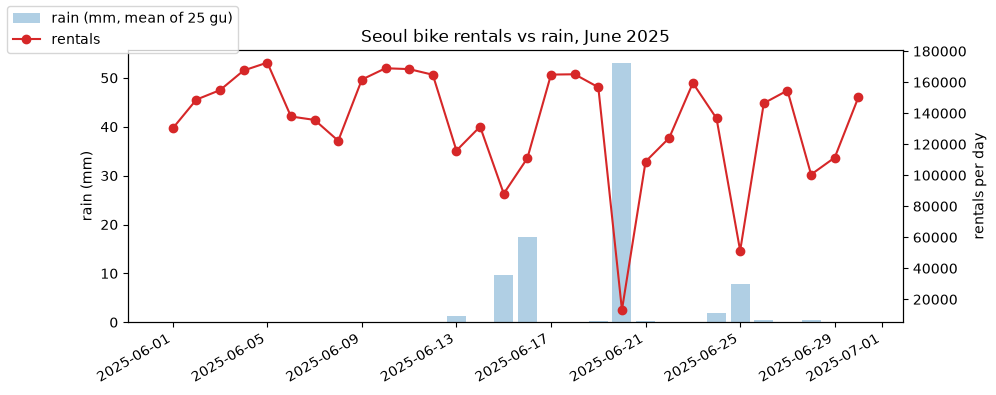

In [ ]:
import matplotlib.pyplot as plt

day = (bike_gu.groupby("rent_date")["rentals"].sum().to_frame()
       .join(gu_rain.groupby("date")["rain_mm"].mean()))

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(day.index, day["rain_mm"], color="tab:blue", alpha=.35, label="rain (mm, mean of 25 gu)")
ax1.set_ylabel("rain (mm)")
ax2 = ax1.twinx()
ax2.plot(day.index, day["rentals"], color="tab:red", marker="o", label="rentals")
ax2.set_ylabel("rentals per day")
ax1.set_title("Seoul bike rentals vs rain, June 2025")
fig.legend(loc="upper left")
fig.autofmt_xdate()
plt.show()

> **확인 포인트** — 파란 막대(비)가 높은 6/15 · 6/16 · 6/20 · 6/25 에 빨간 선(대여)이 크게 내려갑니다.

## 9단계 · 더 해 보기

- 비 오는 날 기준을 1mm 대신 0.5mm · 5mm · 10mm 로 바꿔 보세요. 감소율이 어떻게 달라지나요? 기준을 바꾸면 비 오는 날 수도 바뀌니 `rainy_days` 를 함께 보세요.
- 주말만 따로 계산해 보세요. 평일(출퇴근)과 주말(나들이) 중 어느 쪽이 비에 더 민감할까요?
- 강우량 10분 자료를 시간 단위로 묶으면 「비가 그친 뒤 몇 시간 만에 대여가 돌아오나」도 볼 수 있습니다. 이때는 대여도 시간 단위가 필요합니다 — 1단계 Tip 의 SQL 에 `hour("대여일시")` 를 더해 원본에서 다시 세어 보세요.